## Plotting various graphs with Matplotlib

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Create some example data
np.random.seed(42) # for reproducibility
data = np.random.randint(1, 100, 20)
categories = [f'Category {i}' for i in range(len(data))]

print("Example Data Array:")
print(data)

Example Data Array:
[52 93 15 72 61 21 83 87 75 75 88 24  3 22 53  2 88 30 38  2]


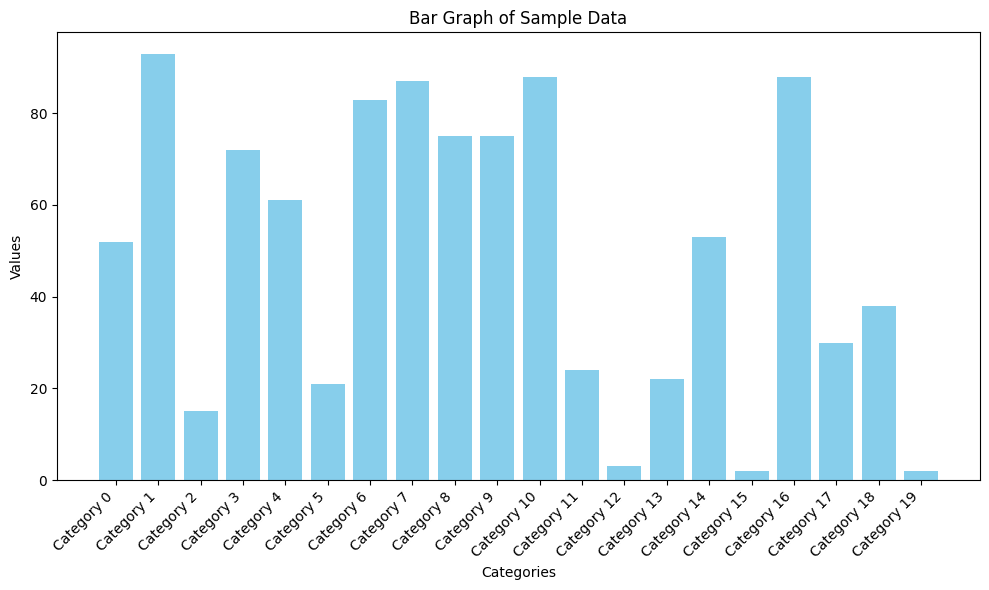

In [ ]:
#bar graph
plt.figure(figsize=(10, 6))
plt.bar(categories, data, color='skyblue')
plt.xlabel('Categories')
plt.ylabel('Values')
plt.title('Bar Graph of Sample Data')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

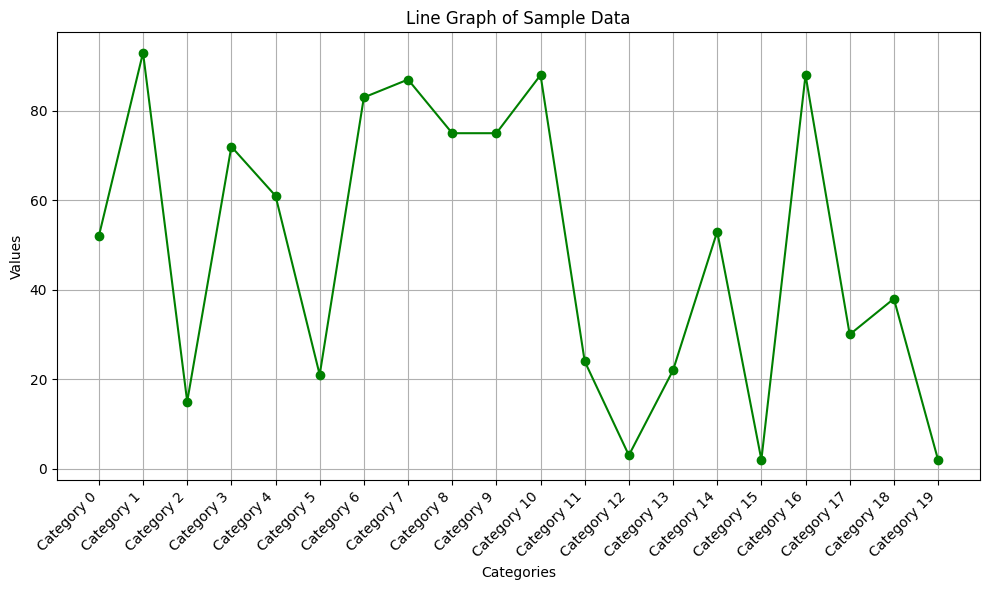

In [ ]:
#line grapgh
plt.figure(figsize=(10, 6))
plt.plot(categories, data, marker='o', linestyle='-', color='green')
plt.xlabel('Categories')
plt.ylabel('Values')
plt.title('Line Graph of Sample Data')
plt.xticks(rotation=45, ha='right')
plt.grid(True)
plt.tight_layout()
plt.show()

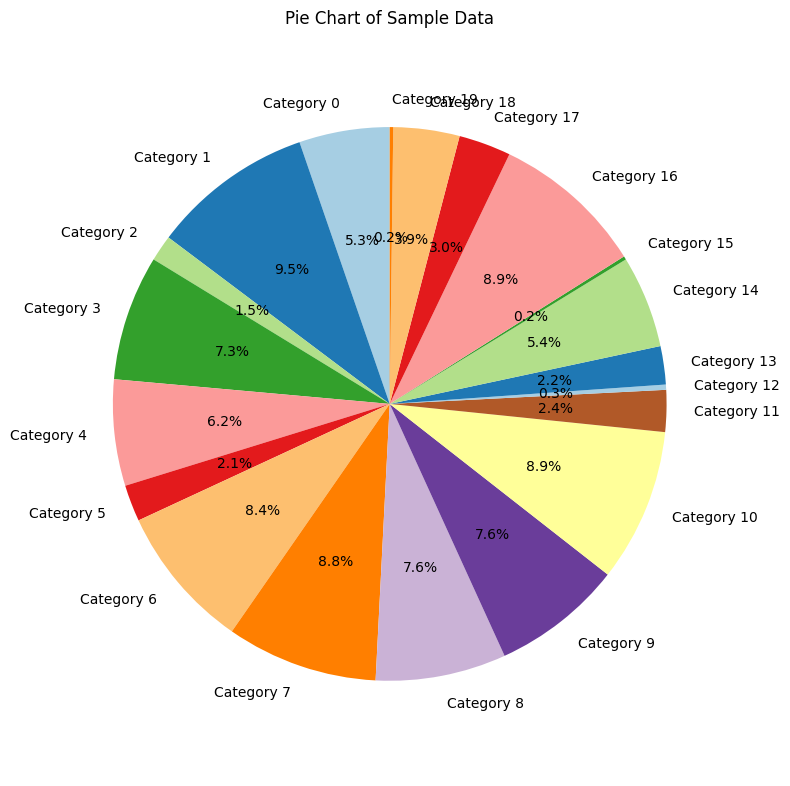

In [ ]:
#pie chart
plt.figure(figsize=(8, 8))
plt.pie(data, labels=categories, autopct='%1.1f%%', startangle=90, colors=plt.cm.Paired.colors)
plt.title('Pie Chart of Sample Data')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()

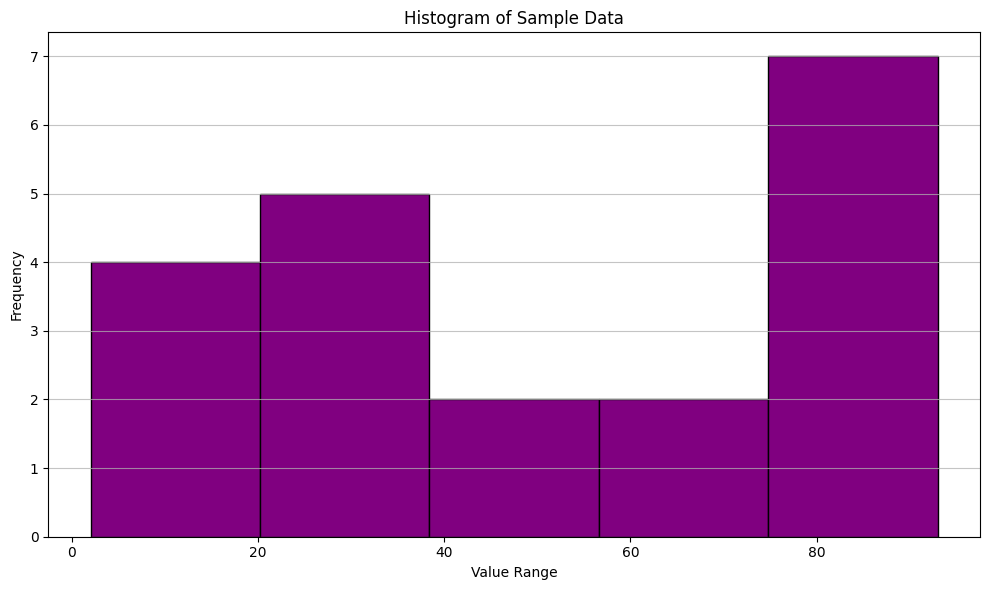

In [ ]:
#histogram
plt.figure(figsize=(10, 6))
plt.hist(data, bins=5, color='purple', edgecolor='black')
plt.xlabel('Value Range')
plt.ylabel('Frequency')
plt.title('Histogram of Sample Data')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

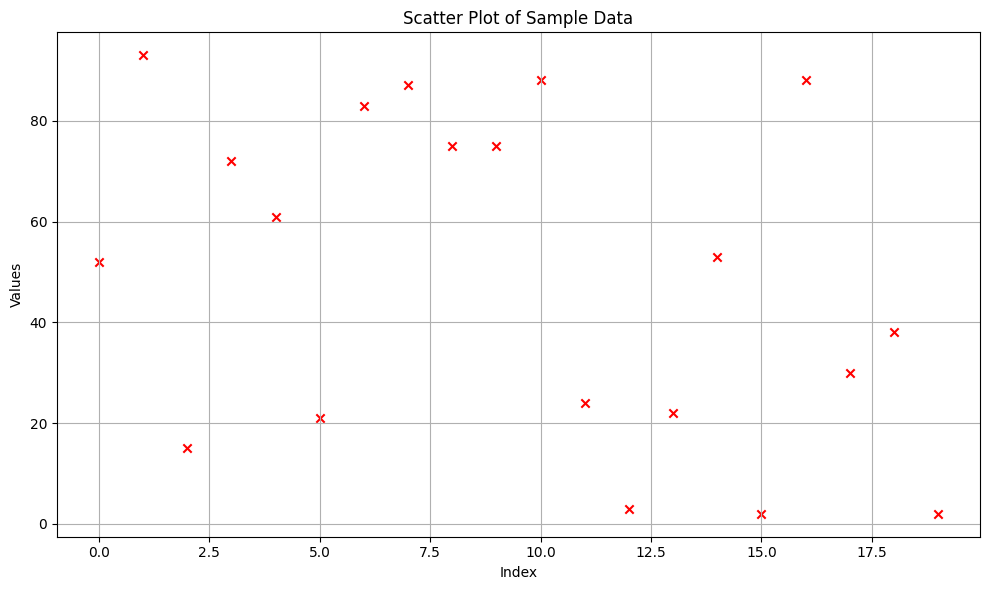

In [ ]:
# scatter plot
x_data = np.arange(len(data))
y_data = data

plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, color='red', marker='x')
plt.xlabel('Index')
plt.ylabel('Values')
plt.title('Scatter Plot of Sample Data')
plt.grid(True)
plt.tight_layout()
plt.show()

---

## Plotting from uploaded files



In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the COVID-19 confirmed cases data
confirmed_df = pd.read_csv('/content/time_series_covid19_confirmed_global.csv')

print("First 5 rows of the Confirmed Cases DataFrame:")
display(confirmed_df.head())

print("\nDataFrame Info:")
confirmed_df.info()

First 5 rows of the Confirmed Cases DataFrame:


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 289 entries, 0 to 288
Columns: 1147 entries, Province/State to 3/9/23
dtypes: float64(2), int64(1143), object(2)
memory usage: 2.5+ MB


In [ ]:
# Melt the DataFrame to transform date columns into rows
# Identify columns that are not dates (fixed identifiers)
id_vars = ['Province/State', 'Country/Region', 'Lat', 'Long']

# Get all date columns by subtracting id_vars from all columns
date_columns = confirmed_df.columns.drop(id_vars)

confirmed_long_df = confirmed_df.melt(id_vars=id_vars,
                                       value_vars=date_columns,
                                       var_name='Date',
                                       value_name='Confirmed_Cases')

# Convert 'Date' column to datetime objects
confirmed_long_df['Date'] = pd.to_datetime(confirmed_long_df['Date'])

# Group by date and sum the confirmed cases globally
global_confirmed_cases = confirmed_long_df.groupby('Date')['Confirmed_Cases'].sum().reset_index()

print("Global Confirmed Cases (first 5 rows):")
display(global_confirmed_cases.head())

print("Global Confirmed Cases (last 5 rows):")
display(global_confirmed_cases.tail())

Global Confirmed Cases (first 5 rows):


/tmp/ipykernel_353/4243382301.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  confirmed_long_df['Date'] = pd.to_datetime(confirmed_long_df['Date'])


,Date,Confirmed_Cases
0,2020-01-22,557
1,2020-01-23,657
2,2020-01-24,944
3,2020-01-25,1437
4,2020-01-26,2120


Global Confirmed Cases (last 5 rows):


,Date,Confirmed_Cases
1138,2023-03-05,676024901
1139,2023-03-06,676082941
1140,2023-03-07,676213378
1141,2023-03-08,676392824
1142,2023-03-09,676570149


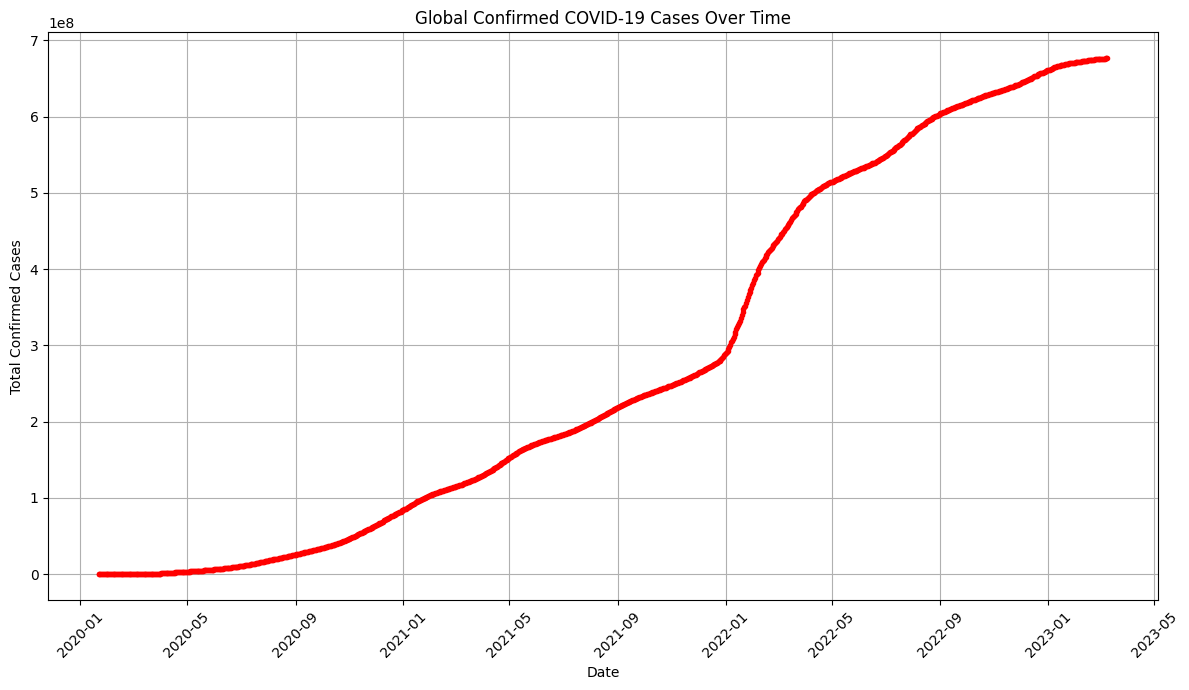

In [ ]:
plt.figure(figsize=(12, 7))
plt.plot(global_confirmed_cases['Date'], global_confirmed_cases['Confirmed_Cases'],
         marker='o', markersize=3, linestyle='-', color='red')

plt.xlabel('Date')
plt.ylabel('Total Confirmed Cases')
plt.title('Global Confirmed COVID-19 Cases Over Time')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

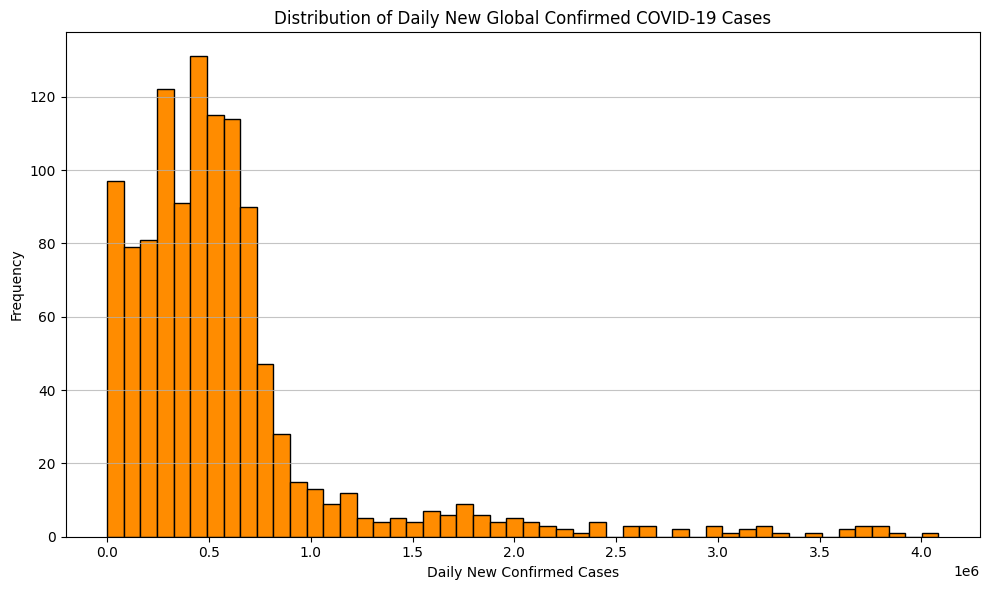

Descriptive statistics for Daily New Cases:


,Confirmed_Cases
count,1.142000e+03
mean,5.924427e+05
std,5.956510e+05
min,1.000000e+02
25%,2.652462e+05
50%,4.739715e+05
75%,6.767745e+05
max,4.083281e+06


In [ ]:
# Calculate daily new cases
daily_new_cases = global_confirmed_cases['Confirmed_Cases'].diff().dropna()

plt.figure(figsize=(10, 6))
plt.hist(daily_new_cases, bins=50, color='darkorange', edgecolor='black')
plt.xlabel('Daily New Confirmed Cases')
plt.ylabel('Frequency')
plt.title('Distribution of Daily New Global Confirmed COVID-19 Cases')
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.show()

print("Descriptive statistics for Daily New Cases:")
display(daily_new_cases.describe())

### Bar Chart: Top 10 Countries by Total Confirmed Cases

To create a bar graph and potentially a pie chart, aggregating the data by country would be useful. Let's find the total confirmed cases for each country on the latest date available and visualize the top 10 countries.

Top 10 Countries by Total Confirmed Cases (as of latest date):


,Country/Region,Confirmed_Cases
0,US,103802702
1,India,44690738
2,France,39866718
3,Germany,38249060
4,Brazil,37076053
5,Japan,33320438
6,"Korea, South",30615522
7,Italy,25603510
8,United Kingdom,24658705
9,Russia,22075858


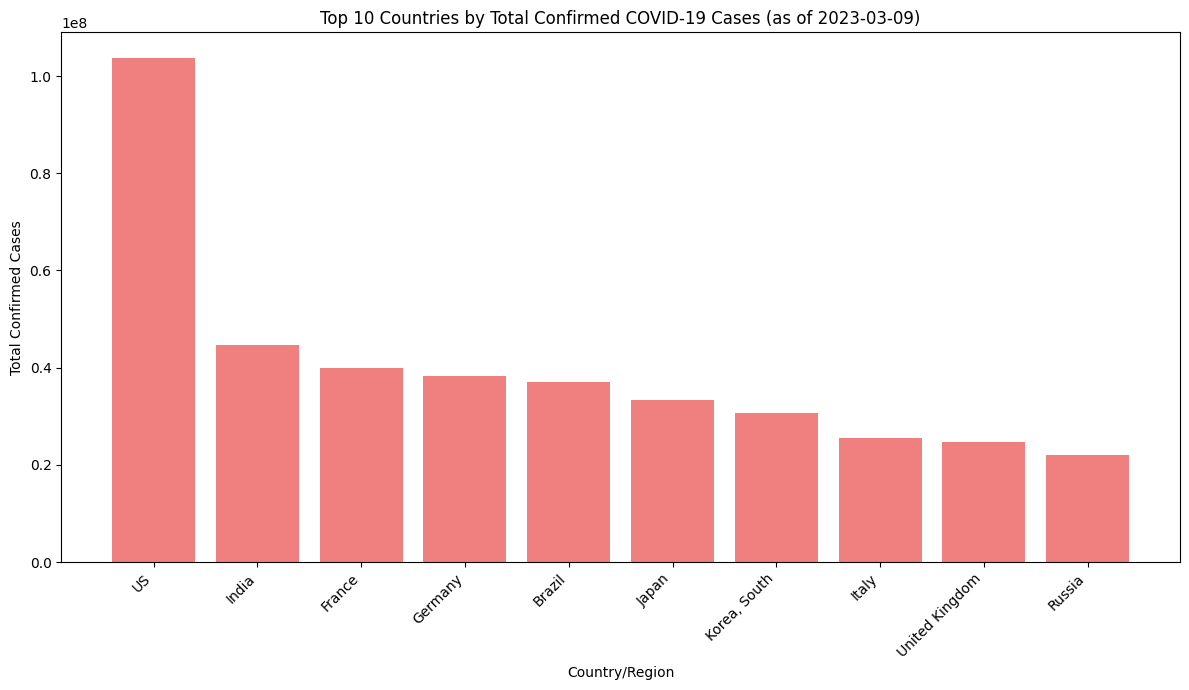

In [ ]:
# Get the latest date in the dataset
latest_date = confirmed_long_df['Date'].max()

# Filter data for the latest date
latest_data = confirmed_long_df[confirmed_long_df['Date'] == latest_date]

# Group by country and sum confirmed cases
country_total_cases = latest_data.groupby('Country/Region')['Confirmed_Cases'].sum().sort_values(ascending=False).reset_index()

# Get the top 10 countries
top_10_countries = country_total_cases.head(10)

print("Top 10 Countries by Total Confirmed Cases (as of latest date):")
display(top_10_countries)

plt.figure(figsize=(12, 7))
plt.bar(top_10_countries['Country/Region'], top_10_countries['Confirmed_Cases'], color='lightcoral')
plt.xlabel('Country/Region')
plt.ylabel('Total Confirmed Cases')
plt.title(f'Top 10 Countries by Total Confirmed COVID-19 Cases (as of {latest_date.strftime("%Y-%m-%d")})')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Pie Chart: Proportion of Cases in Top 10 Countries

Now, let's visualize the proportion of total cases accounted for by these top 10 countries using a pie chart. We'll also include an 'Other Countries' slice for the rest.

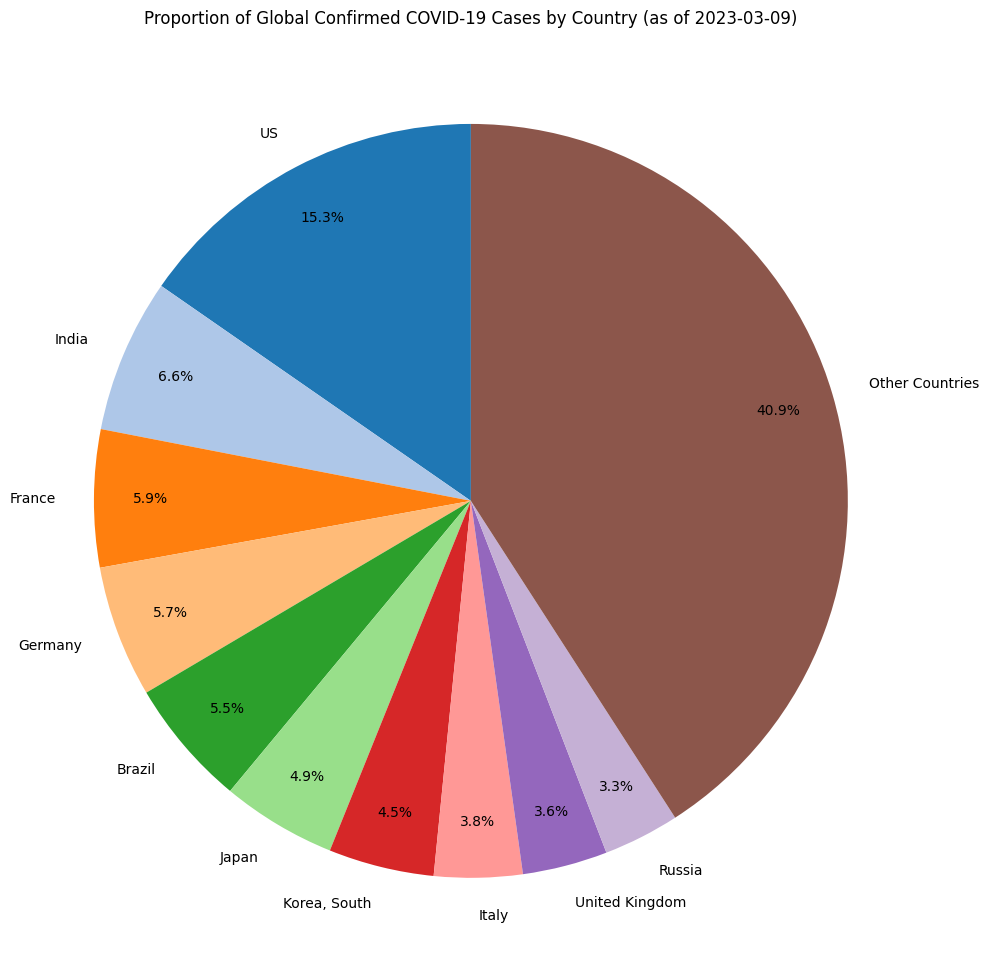

In [ ]:
# Calculate total cases for all other countries
other_countries_cases = country_total_cases['Confirmed_Cases'].iloc[10:].sum()

# Prepare data for pie chart: top 10 and 'Other Countries'
pie_data = top_10_countries.copy()
pie_data.loc[len(pie_data)] = ['Other Countries', other_countries_cases]

plt.figure(figsize=(10, 10))
plt.pie(pie_data['Confirmed_Cases'], labels=pie_data['Country/Region'], autopct='%1.1f%%', startangle=90,
        colors=plt.cm.tab20.colors, pctdistance=0.85)
plt.title(f'Proportion of Global Confirmed COVID-19 Cases by Country (as of {latest_date.strftime("%Y-%m-%d")})')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()

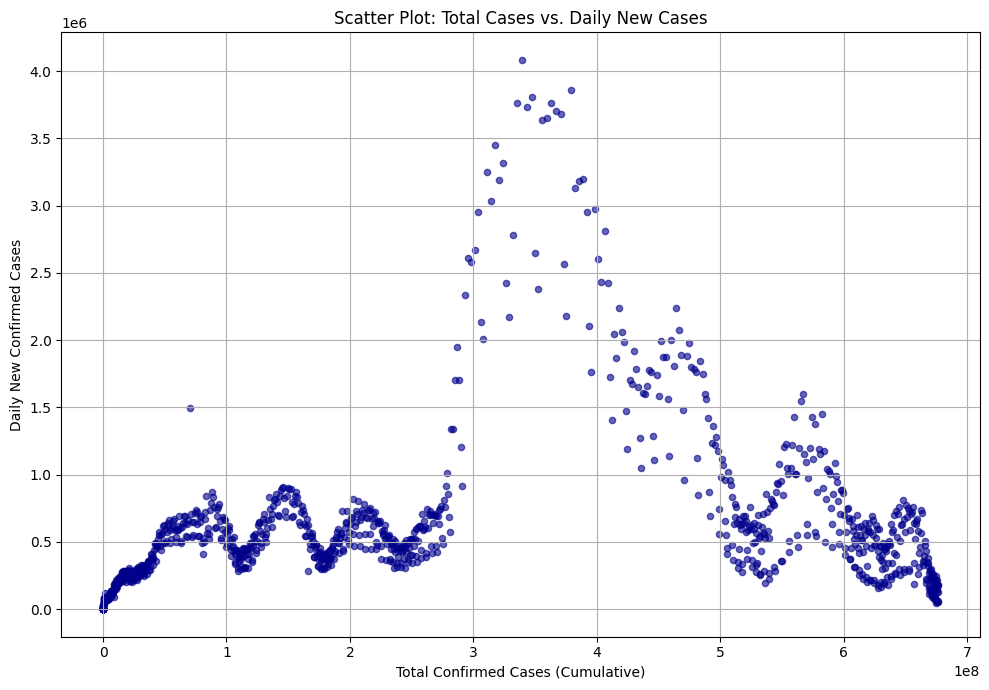

In [ ]:
scatter_df = global_confirmed_cases.set_index('Date').copy()
# Calculate daily new cases directly on the indexed DataFrame to ensure alignment
scatter_df['Daily_New_Cases'] = scatter_df['Confirmed_Cases'].diff()
scatter_df = scatter_df.dropna()

plt.figure(figsize=(10, 7))
plt.scatter(scatter_df['Confirmed_Cases'], scatter_df['Daily_New_Cases'],
            alpha=0.6, color='darkblue', s=20)
plt.xlabel('Total Confirmed Cases (Cumulative)')
plt.ylabel('Daily New Confirmed Cases')
plt.title('Scatter Plot: Total Cases vs. Daily New Cases')
plt.grid(True)
plt.tight_layout()
plt.show()

---

## Performing Boxplot on Kaggle Dataset

Using Colab cache for faster access to the 'test-file' dataset.
Path to dataset files: /kaggle/input/test-file
Files in the downloaded dataset:
/kaggle/input/test-file/tested.csv

Loading data from: /kaggle/input/test-file/tested.csv

First 5 rows of the Kaggle DataFrame:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Survived     418 non-null    int64  
 2   Pclass       418 non-null    int64  
 3   Name         418 non-null    object 
 4   Sex          418 non-null    object 
 5   Age          332 non-null    float64
 6   SibSp        418 non-null    int64  
 7   Parch        418 non-null    int64  
 8   Ticket       418 non-null    object 
 9   Fare         417 non-null    float64
 10  Cabin        91 non-null     object 
 11  Embarked     418 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 39.3+ KB

Numerical columns found: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']


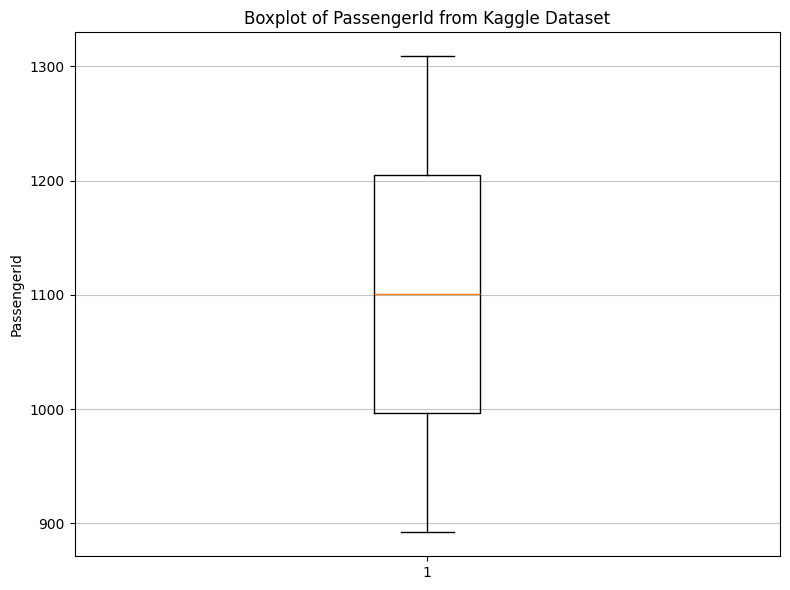

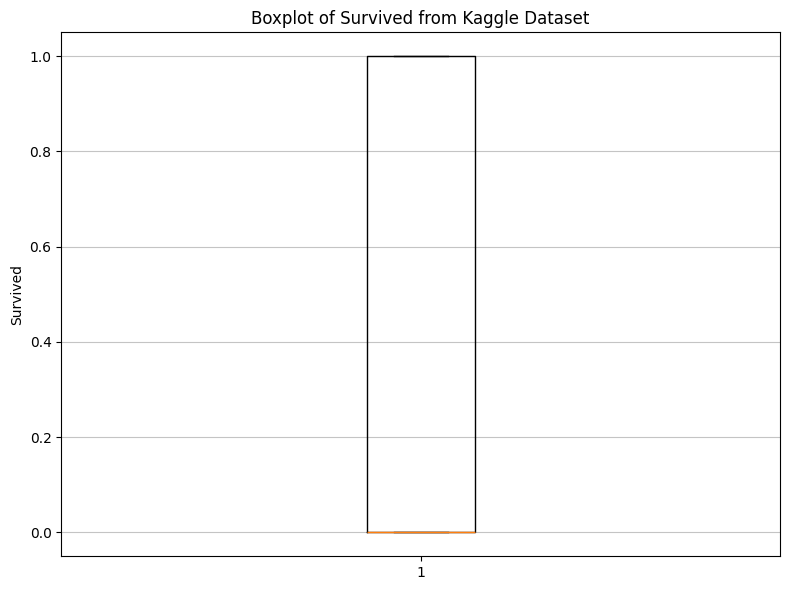

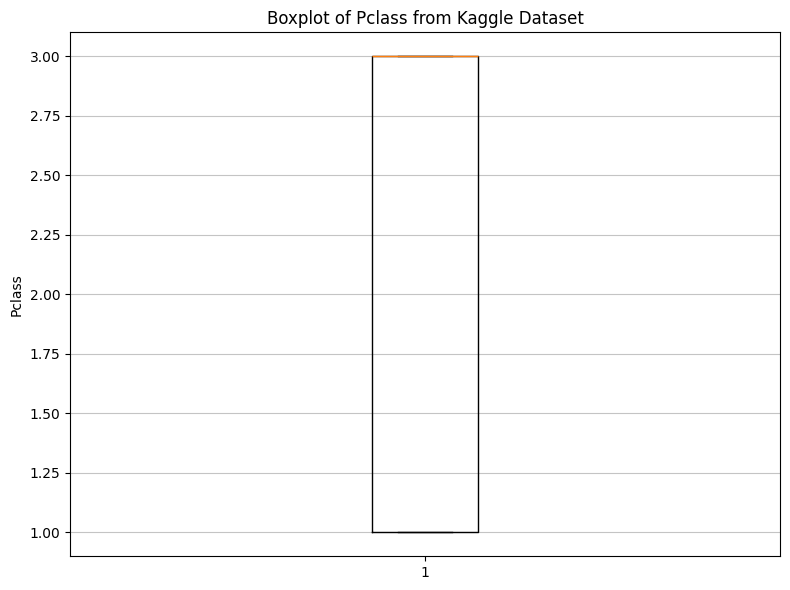

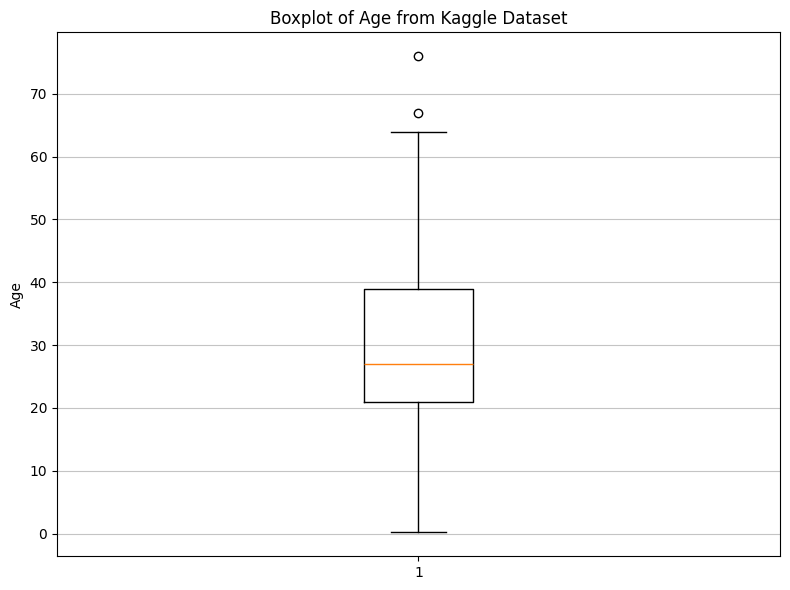

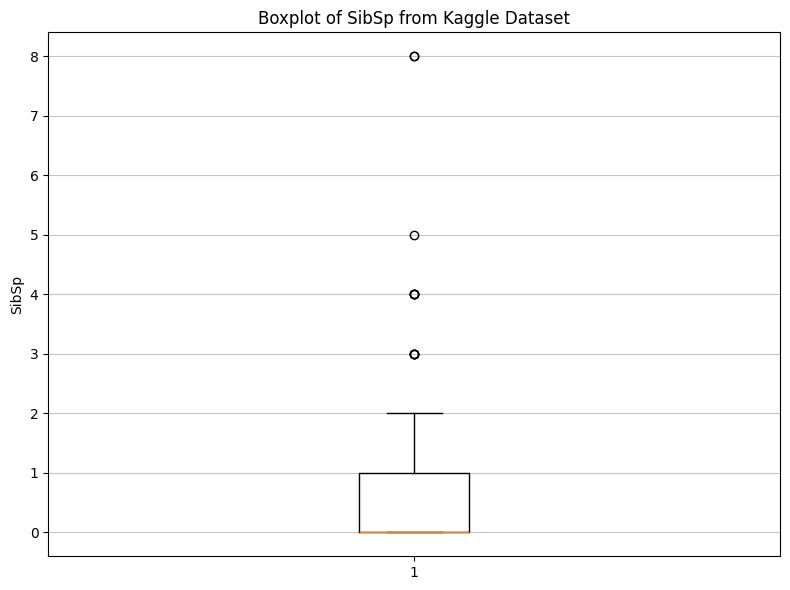

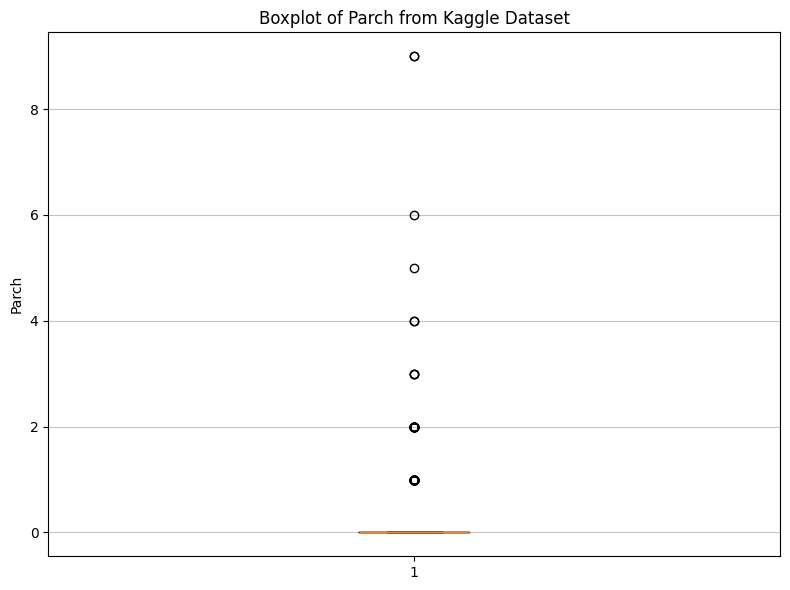

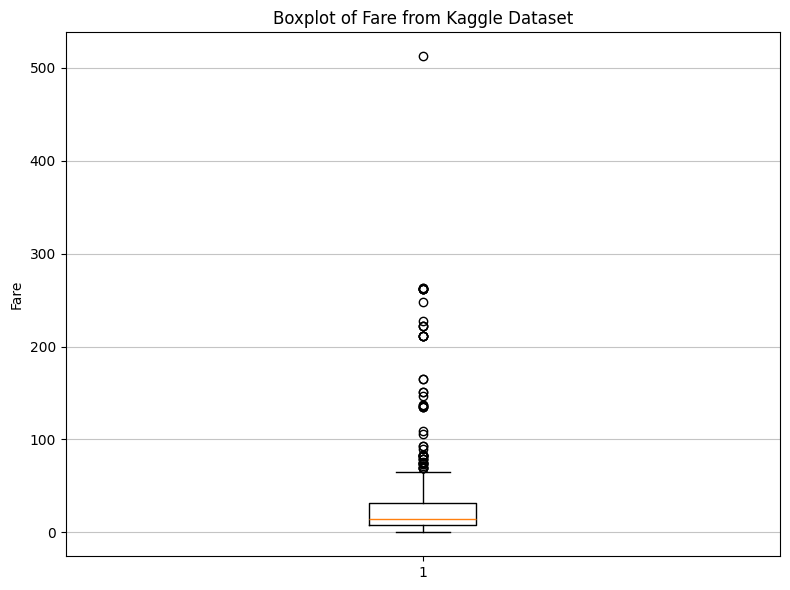

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import os

# Download latest version of the dataset
path = kagglehub.dataset_download("brendan45774/test-file")

print("Path to dataset files:", path)

# List files in the downloaded directory
print("Files in the downloaded dataset:")
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

# Assuming the dataset contains a CSV, try to load the first one found
csv_files = [os.path.join(root, file) for root, dirs, files in os.walk(path) for file in files if file.endswith('.csv')]

if csv_files:
    data_file_path = csv_files[0]
    print(f"\nLoading data from: {data_file_path}")
    kaggle_df = pd.read_csv(data_file_path)

    print("\nFirst 5 rows of the Kaggle DataFrame:")
    display(kaggle_df.head())

    print("\nDataFrame Info:")
    kaggle_df.info()

    # Identify numerical columns for boxplots
    numerical_cols = kaggle_df.select_dtypes(include=np.number).columns

    if not numerical_cols.empty:
        print(f"\nNumerical columns found: {list(numerical_cols)}")
        # Create boxplots for each numerical column
        for col in numerical_cols:
            plt.figure(figsize=(8, 6))
            plt.boxplot(kaggle_df[col].dropna())
            plt.ylabel(col)
            plt.title(f'Boxplot of {col} from Kaggle Dataset')
            plt.grid(axis='y', alpha=0.75)
            plt.tight_layout()
            plt.show()
    else:
        print("No numerical columns found in the dataset for boxplotting.")
else:
    print("No CSV files found in the downloaded dataset. Cannot perform boxplot.")